<a href="https://colab.research.google.com/github/arupkumarm123/SmartCampaign/blob/master/sample_statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

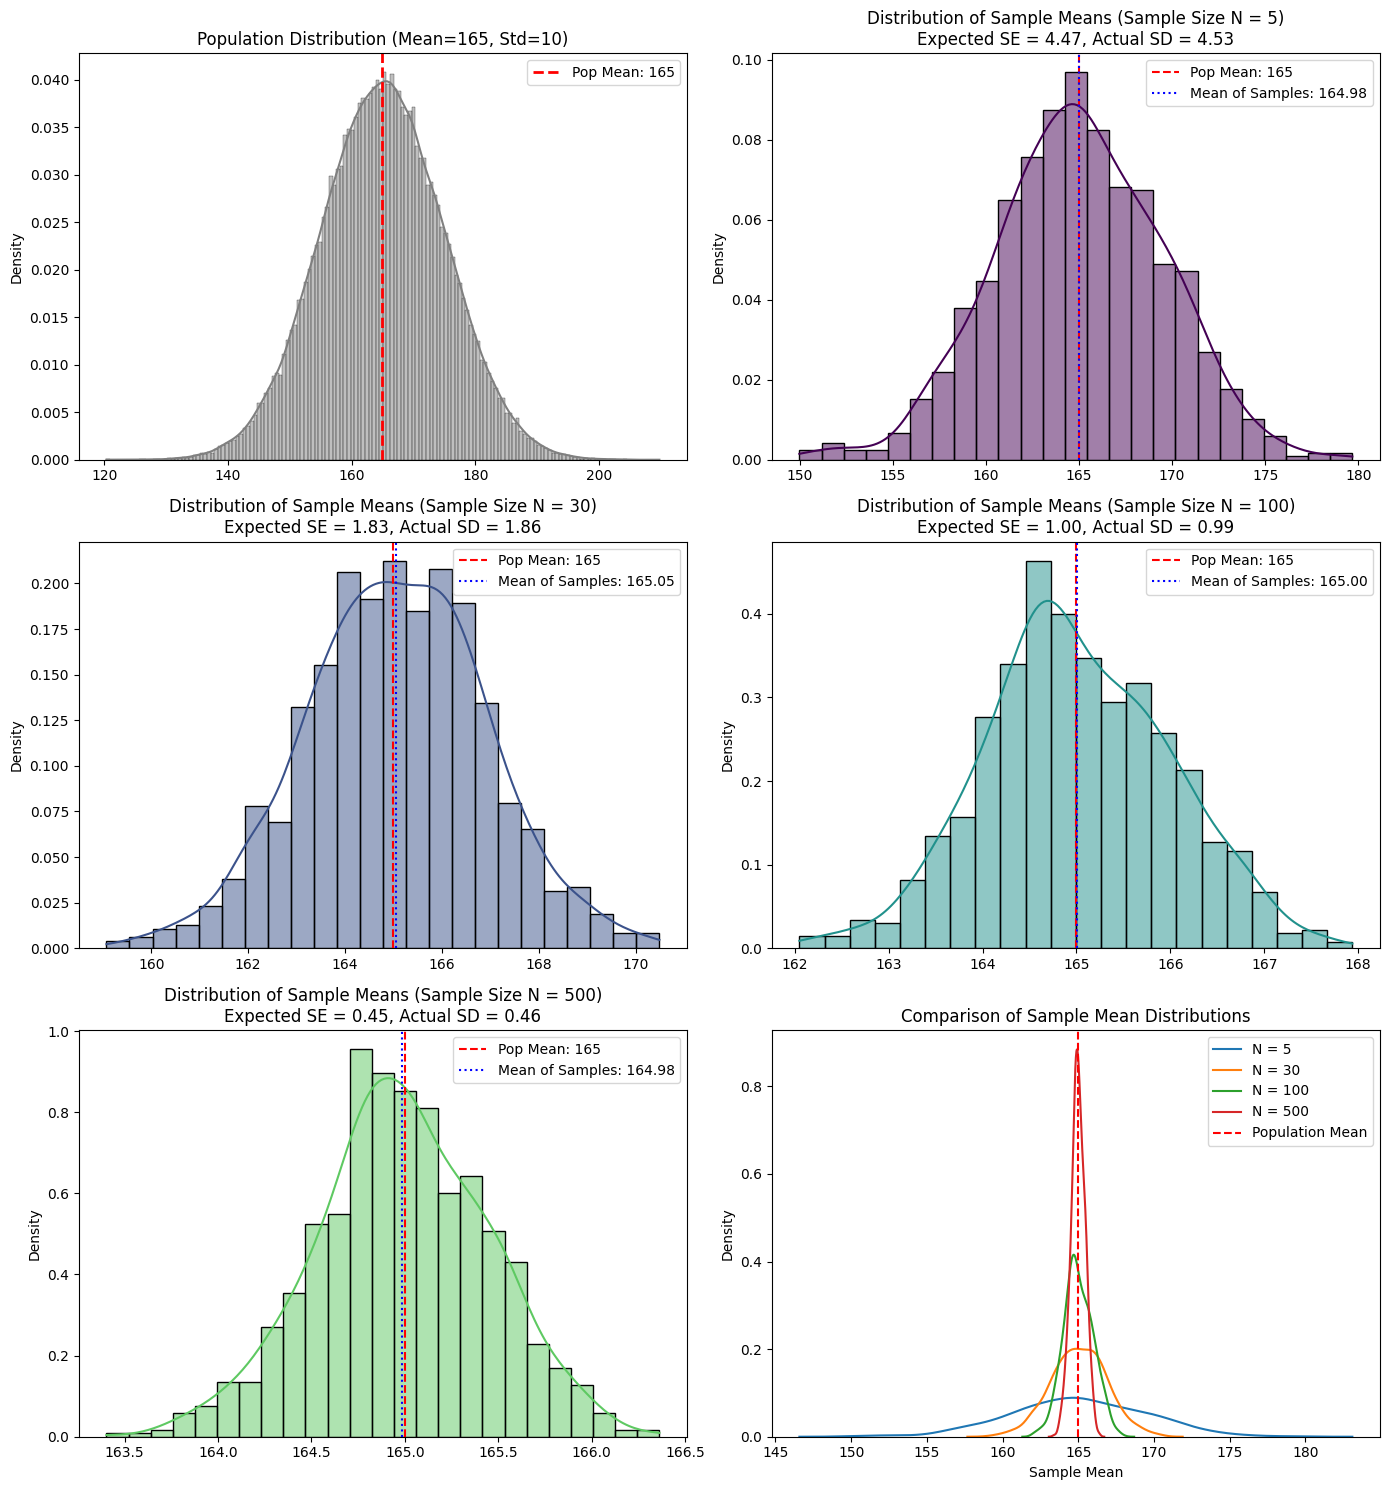

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define Population Parameters
population_mean = 165
population_std = 10
np.random.seed(42)  # For reproducibility

# Generate population data for visualization
population = np.random.normal(population_mean, population_std, 100000)

# 2. Simulation Parameters
sample_sizes = [5, 30, 100, 500]
num_simulations = 1000

# Dictionary to store sample means for each sample size
sample_means_dict = {}

# Run the simulation
for size in sample_sizes:
    # Draw 'num_simulations' samples of size 'size' from the population
    samples = np.random.normal(population_mean, population_std, (num_simulations, size))
    # Calculate the mean of each sample
    sample_means_dict[size] = np.mean(samples, axis=1)

# 3. Plotting the results
fig, axes = plt.subplots(3, 2, figsize=(14, 15), sharex=False)
axes = axes.flatten()

# Plot Population Distribution
sns.histplot(population, kde=True, color='gray', ax=axes[0], stat='density')
axes[0].axvline(population_mean, color='red', linestyle='--', linewidth=2, label=f'Pop Mean: {population_mean}')
axes[0].set_title(f'Population Distribution (Mean={population_mean}, Std={population_std})')
axes[0].legend()

# Plot Sample Means Distributions for different sample sizes
for i, size in enumerate(sample_sizes):
    ax_idx = i + 1
    means = sample_means_dict[size]
    expected_std_error = population_std / np.sqrt(size)

    sns.histplot(means, kde=True, color=plt.cm.viridis(i / len(sample_sizes)), ax=axes[ax_idx], stat='density')
    axes[ax_idx].axvline(population_mean, color='red', linestyle='--', linewidth=1.5, label=f'Pop Mean: {population_mean}')
    axes[ax_idx].axvline(np.mean(means), color='blue', linestyle=':', linewidth=1.5, label=f'Mean of Samples: {np.mean(means):.2f}')
    axes[ax_idx].set_title(f'Distribution of Sample Means (Sample Size N = {size})\nExpected SE = {expected_std_error:.2f}, Actual SD = {np.std(means):.2f}')
    axes[ax_idx].legend()

# Plot a comparison of all sampling distributions
for i, size in enumerate(sample_sizes):
    sns.kdeplot(sample_means_dict[size], label=f'N = {size}', ax=axes[5])
axes[5].axvline(population_mean, color='red', linestyle='--', label='Population Mean')
axes[5].set_title('Comparison of Sample Mean Distributions')
axes[5].set_xlabel('Sample Mean')
axes[5].legend()

plt.tight_layout()
plt.show()

### Understanding the Concepts

Based on the simulation above, we can highlight several fundamental concepts in statistics:

#### 1. Population vs. Sample Parameters
*   **Population Mean ($\mu$) & Standard Deviation ($\sigma$):** Fixed, usually unknown values representing the entire group (in our case, $\mu = 165$ and $\sigma = 10$).
*   **Sample Mean ($\bar{x}$) & Standard Deviation ($s$):** Variables computed from a subset of the population. These values vary from sample to sample due to sampling error.

#### 2. The Law of Large Numbers (LLN)
As the sample size $N$ increases, the sample mean $\bar{x}$ gets closer to the population mean $\mu$. In our plots:
*   With $N = 5$, individual sample means fluctuate widely around 165.
*   With $N = 500$, the sample means cluster very tightly near 165.

#### 3. The Central Limit Theorem (CLT)
Regardless of the shape of the population distribution (though our population is normal here), the distribution of the sample means tends towards a normal distribution as the sample size increases.

#### 4. Standard Error (SE)
The standard deviation of the sampling distribution of the mean is called the **Standard Error**:

$$\text{SE} = \frac{\sigma}{\sqrt{N}}$$

*   As sample size $N$ increases, the Standard Error decreases.
*   This is visible in our simulation: for $N = 5$, the Standard Error is $\approx 4.47$, whereas for $N = 500$, it drops significantly to $\approx 0.45$, leading to a much narrower distribution.

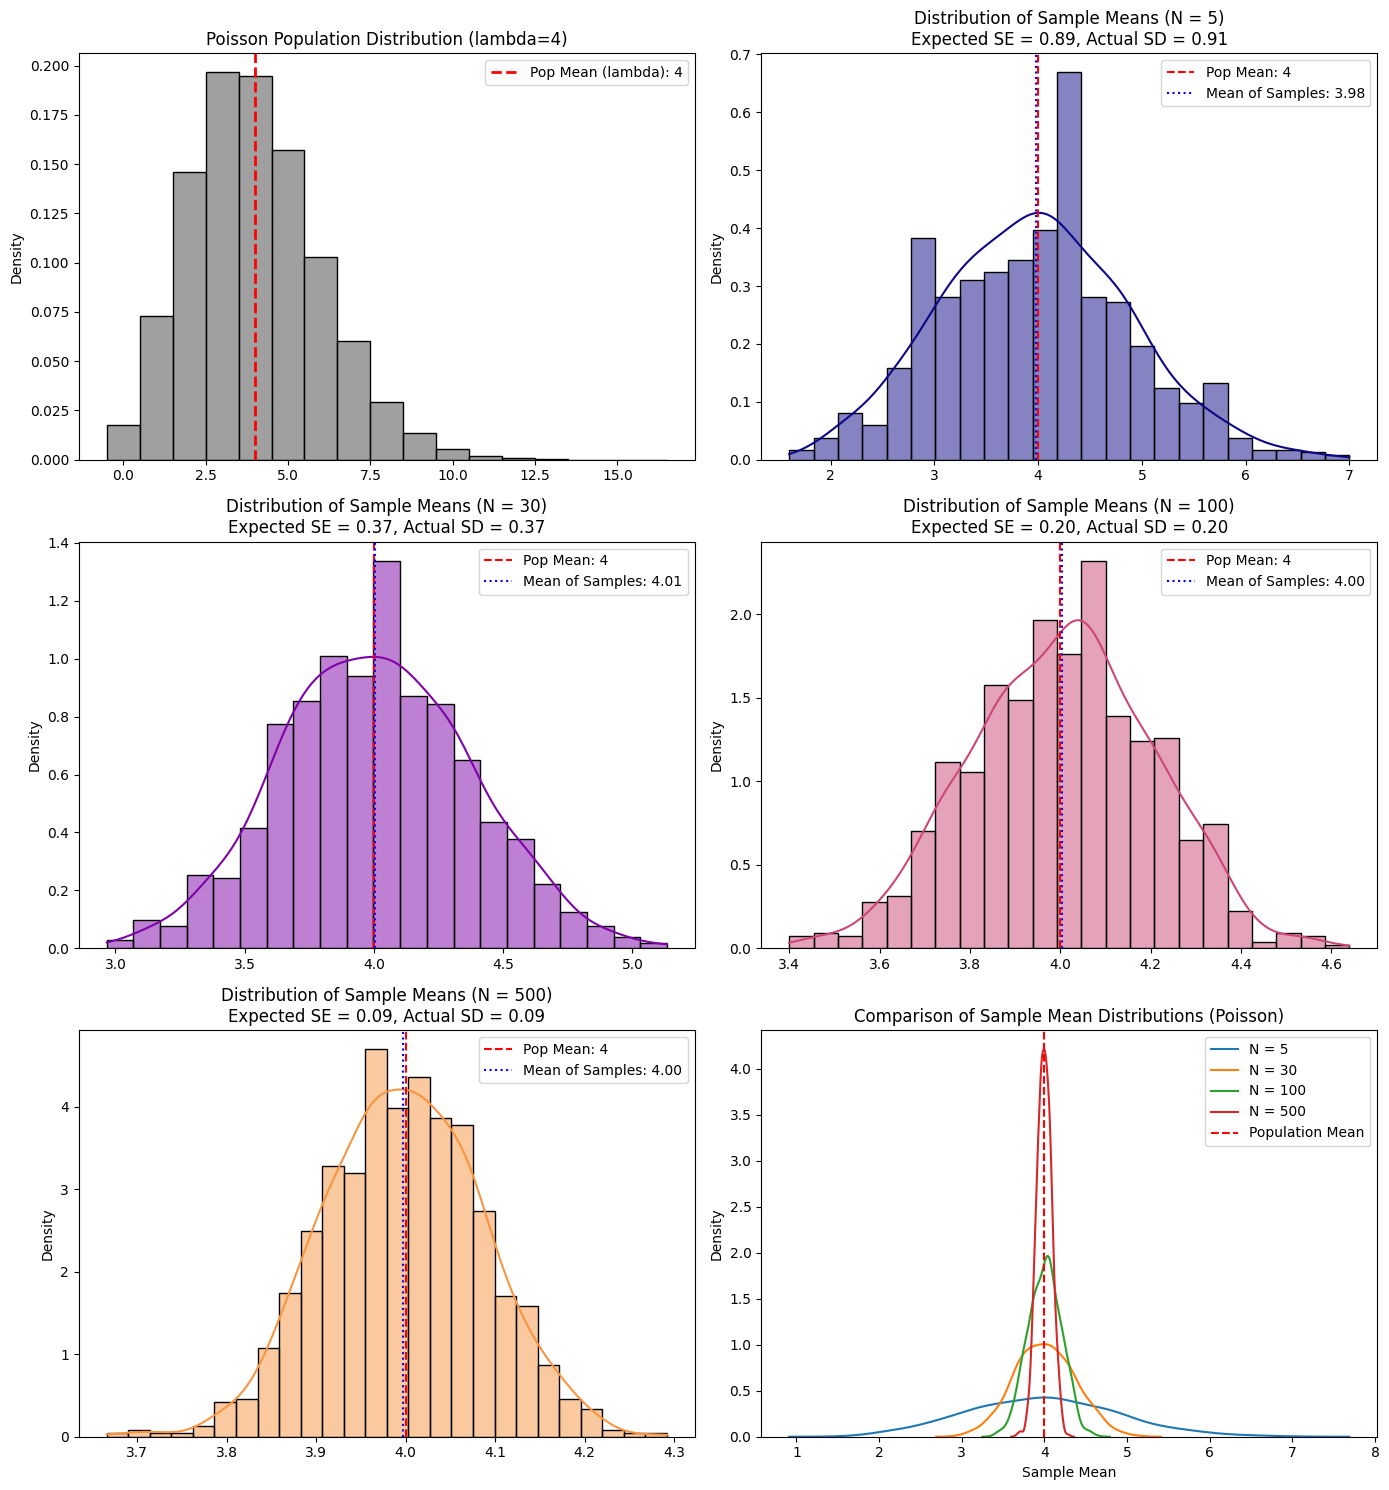

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define Poisson Population Parameters
# Let's choose a mean (lambda) of 4. This distribution is visibly skewed.
population_lam = 4
np.random.seed(42)

# Generate population data for visualization
population_poisson = np.random.poisson(lam=population_lam, size=100000)

# 2. Simulation Parameters
sample_sizes = [5, 30, 100, 500]
num_simulations = 1000

sample_means_poisson = {}

# Run the simulation
for size in sample_sizes:
    samples = np.random.poisson(lam=population_lam, size=(num_simulations, size))
    sample_means_poisson[size] = np.mean(samples, axis=1)

# 3. Plotting the results
fig, axes = plt.subplots(3, 2, figsize=(14, 15), sharex=False)
axes = axes.flatten()

# Plot Population Distribution (Discrete PMF represented as a bar plot or hist)
sns.histplot(population_poisson, discrete=True, color='gray', ax=axes[0], stat='density')
axes[0].axvline(population_lam, color='red', linestyle='--', linewidth=2, label=f'Pop Mean (lambda): {population_lam}')
axes[0].set_title(f'Poisson Population Distribution (lambda={population_lam})')
axes[0].legend()

# Plot Sample Means Distributions
for i, size in enumerate(sample_sizes):
    ax_idx = i + 1
    means = sample_means_poisson[size]
    # For a Poisson distribution, variance = mean (lambda), so std dev = sqrt(lambda)
    expected_std_error = np.sqrt(population_lam) / np.sqrt(size)

    sns.histplot(means, kde=True, color=plt.cm.plasma(i / len(sample_sizes)), ax=axes[ax_idx], stat='density')
    axes[ax_idx].axvline(population_lam, color='red', linestyle='--', linewidth=1.5, label=f'Pop Mean: {population_lam}')
    axes[ax_idx].axvline(np.mean(means), color='blue', linestyle=':', linewidth=1.5, label=f'Mean of Samples: {np.mean(means):.2f}')
    axes[ax_idx].set_title(f'Distribution of Sample Means (N = {size})\nExpected SE = {expected_std_error:.2f}, Actual SD = {np.std(means):.2f}')
    axes[ax_idx].legend()

# Plot comparison of all sampling distributions
for i, size in enumerate(sample_sizes):
    sns.kdeplot(sample_means_poisson[size], label=f'N = {size}', ax=axes[5])
axes[5].axvline(population_lam, color='red', linestyle='--', label='Population Mean')
axes[5].set_title('Comparison of Sample Mean Distributions (Poisson)')
axes[5].set_xlabel('Sample Mean')
axes[5].legend()

plt.tight_layout()
plt.show()

### Key Observations from the Poisson Simulation

#### 1. Overcoming Skewness (The Central Limit Theorem in Action)
*   The original **Poisson population distribution** (top left) is heavily skewed to the right and discrete.
*   At a very small sample size ($N = 5$), the distribution of the sample means is still somewhat bumpy and skewed.
*   As the sample size increases to $N = 30$ and larger, the distribution of sample means becomes remarkably symmetric, smooth, and **bell-shaped (normal)**. This is a powerful demonstration of the Central Limit Theorem: the sampling distribution of the mean approaches normality even when the population distribution is non-normal.

#### 2. Standard Error of the Poisson Mean
For a Poisson population, both the mean and the variance are equal to $\lambda$. Therefore, the population standard deviation is $\sigma = \sqrt{\lambda}$.

The standard error (SE) of the sample mean is:

$$\text{SE} = \frac{\sqrt{\lambda}}{\sqrt{N}}$$

Just as with the normal distribution, we see that the spread of the sample means shrinks precisely by a factor of $\sqrt{N}$ as $N$ increases.

# New Section